In [9]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler
from evaluationFunction     import compute_average_hi_metrics

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


In [10]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

#### Preprocessing data

In [11]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir              = outputDir, 
                                                   name             = "data/teps.h5",
                                                   case             = "all", 
                                                   reduceSampleRate = True, 
                                                   removeHigherThr  = False)

withRULData         = preData.addRULAndEnvironment(rawData)
# withoutInitRawData  = preData.removeInitState(inData= withRULData)



# ---------------------------
# For data
cleanData           = preData.cleanData(rawSignal           =   withRULData,
                                        columnName          =   preData.allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
norData             = preData.normalizeDataEachModes(rawData    = cleanData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"])    # Normalize the data



Process:41053||2025-06-12 15:12:11,416-INFO [preProcessingDataTEP.py:loadDataFromH5Format():357]:Loading data from H5 files ...
Process:41053||2025-06-12 15:12:12,463-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:41053||2025-06-12 15:12:12,688-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:41053||2025-06-12 15:12:12,690-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:41053||2025-06-12 15:12:12,691-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:41053||2025-06-12 15:12:12,692-INFO [preProcessingDataTEP.py:normalizeDataEachModes():800]:Normalizing the data ...


#### Declare the model

In [12]:
config["component"] = "Sys"
vaeSys = SystemModel(config = config)
vaeSys.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
vaeSys.summary()

modelDirComp1 = outputDir + "checkpoint/" + "bestModel34Reac"
modelDirComp2 = outputDir + "checkpoint/" + "bestModel35Sep"
modelDirComp3 = outputDir + "checkpoint/" + "bestModel36Strip"
modelDirSys   = outputDir + "checkpoint/" + "bestModel38Sys"
vaeSys.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:41053||2025-06-12 15:12:16,147-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():923]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip


The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:41053||2025-06-12 15:12:16,182-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():962]:Loaded the model at the direction:('/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip') and freezed it successfully!!!
Process:41053||2025-06-12 15:12:16,196-DEBUG [tepSystemModel.py:__init__():313]:The shape of hiSelectionInput (None, 120)
Process:41053||2025-06-12 15:12:16,224-DEBUG [tepSystemModel.py:__init__():321]:The shape of multiplied matrix (None, 3)
Process:41053||2025-06-12 15:12:16,241-DEBUG [tepSystemModel.py:__init__():331]:The shape of min, max and linear HI (TensorShape([None, 1]), TensorShape([None, 1]), TensorShape([None, 1]))
Process:41053||2025-06-12 15:12:16,245-DEBUG [tepSystemModel.py:__init__():334]:The shape after concatenation (None, 3)
Process:41053||2025-06-12

-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
Model: "system_model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection_3 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_4 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_5 (SensorS  multiple                 135       
 election)                  

Process:41053||2025-06-12 15:12:17,521-INFO [tepSystemModel.py:load_weights():888]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys
Process:41053||2025-06-12 15:12:17,564-INFO [tepSystemModel.py:load_weights():920]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys successfully!!!


### MAKS EACH COMPONENT IN EACH ENVIRONMENT

#### Reactor

In [13]:
binaryMaskReac, probsReac     = vaeSys.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |      1.0      |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |      1.0      |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    |  1.065079e-12 |  0.0   |
| 8  |       msv A Feed       |  1.059976e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |      1.0      |  1.0   |
| 11 |    msv A and C Feed    |      1.0      |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Separator

In [14]:
binaryMaskReac, probsReac     = vaeSys.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)



The number of selected sensor in the environment 1 is 13.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 4.6886475e-13 |  0.0   |
| 1  |         A Feed         | 4.6633183e-13 |  0.0   |
| 2  |      A and C Feed      | 4.6340227e-13 |  0.0   |
| 3  |         Purge          | 4.6123657e-13 |  0.0   |
| 4  |       Separator        |  4.627496e-13 |  0.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 4.5894007e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 4.6479915e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 4.6254927e-13 |  0.0   |
| 11 |    msv A and C Feed    | 4.5658963e-13 |  0.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Stripper

In [15]:
binaryMaskReac, probsReac     = vaeSys.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 19.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 1.7232655e-13 |  0.0   |
| 1  |         A Feed         |  1.670584e-13 |  0.0   |
| 2  |      A and C Feed      | 1.9034903e-13 |  0.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        | 1.9865823e-13 |  0.0   |
| 6  |    Reactor Coolant     | 1.6826333e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 1.6601526e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 1.6638454e-13 |  0.0   |
| 11 |    msv A and C Feed    | 1.7078405e-13 |  0.0   |
| 12 |      Recycle Flow      | 1.5469925e-13 |  0.0   |
| 13 |   Reactor Feed Rate   

### HI FOR EACH ENVIRONMENT

#### Environment 2

In [16]:
environmentIdx      = 2
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]


    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # print("---------------======================")
    # print(predictedRul.shape)
    # print(seqXRulTrain[:,-1,:].shape)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)



Process:41053||2025-06-12 15:12:18,405-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:12:18,831-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:12:19,306-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------


... (190 outputs left out)

Process:41053||2025-06-12 15:13:02,619-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1269, 1, 45)
(1269, 128, 45)
(1269, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1269, 1, 45)
(1269, 128, 45)
(1269, 128, 45)
-------------------------------
Getting the HI at the idx 99
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:13:03,036-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------


In [17]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
# dfHI["reacHI"] = (
#     dfHI.groupby("id")["reacHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["sepHI"] = (
#     dfHI.groupby("id")["sepHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["stripHI"] = (
#     dfHI.groupby("id")["stripHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )   
# dfHI["sysHI"] = (
#     dfHI.groupby("id")["sysHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["reacHI"]  = dfHI["reacHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sepHI"]   = dfHI["sepHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["stripHI"] = dfHI["stripHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sysHI"]   = dfHI["sysHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data


dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.44245967
Average Trendability: 0.9225506967534226
Average Monotonicity: 1.0
------------------ Separator -----------------
Average Robustness: 1.0
Average Trendability: nan
Average Monotonicity: 0.0
------------------ Stripper -----------------
Average Robustness: 0.47154674
Average Trendability: 0.8190850489068616
Average Monotonicity: 1.0
------------------ System -----------------
Average Robustness: 0.4724234
Average Trendability: 0.8117269741443038
Average Monotonicity: 1.0


In [18]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]


# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 2.7411088981026013


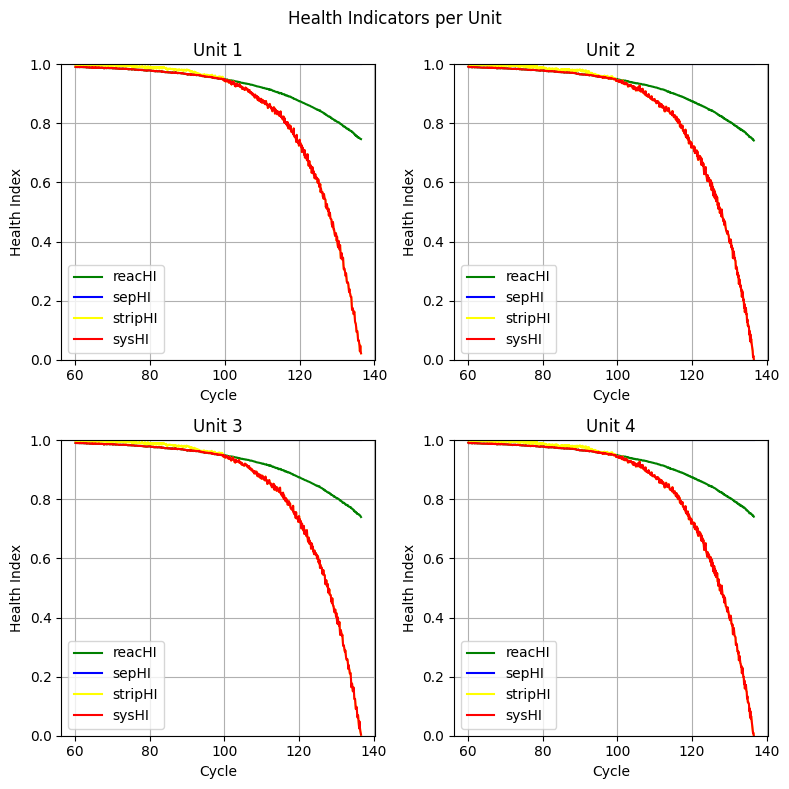

In [19]:
plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
    num_rows=2,
    num_cols=2,
    colors=['green','blue', 'yellow','red'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


In [20]:
# plot1 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [21]:
# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw,color=['g'], numRow=20, numCol=5)

In [22]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 3

In [23]:
environmentIdx      = 3
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:41053||2025-06-12 15:13:10,941-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:13:11,435-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:13:11,900-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------


... (190 outputs left out)

Process:41053||2025-06-12 15:14:01,670-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:14:02,709-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------


In [24]:
print(hiEnv1["Reac"][1])

tf.Tensor([1.0000026 1.0000026 1.0000026 ... 1.0000026 1.0000026 1.0000026], shape=(1250,), dtype=float32)


In [25]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 1.0
Average Trendability: nan
Average Monotonicity: 0.0
------------------ Separator -----------------
Average Robustness: 0.442399
Average Trendability: 0.9162435186049693
Average Monotonicity: 0.864189723320158
------------------ Stripper -----------------
Average Robustness: 0.4726579
Average Trendability: 0.8077261009367711
Average Monotonicity: 0.6989328063241105
------------------ System -----------------
Average Robustness: 0.47371417
Average Trendability: 0.8027770239733185
Average Monotonicity: 0.8146245059288539


In [26]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 3.7583555843119325


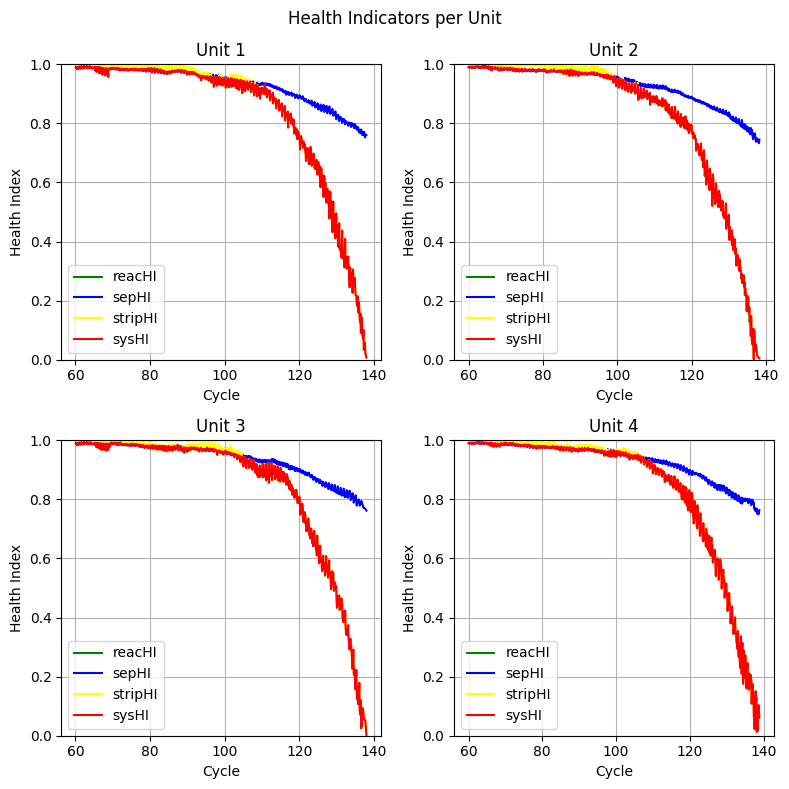

In [27]:
plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
    num_rows=2,
    num_cols=2,
    colors=['green','blue', 'yellow','red'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


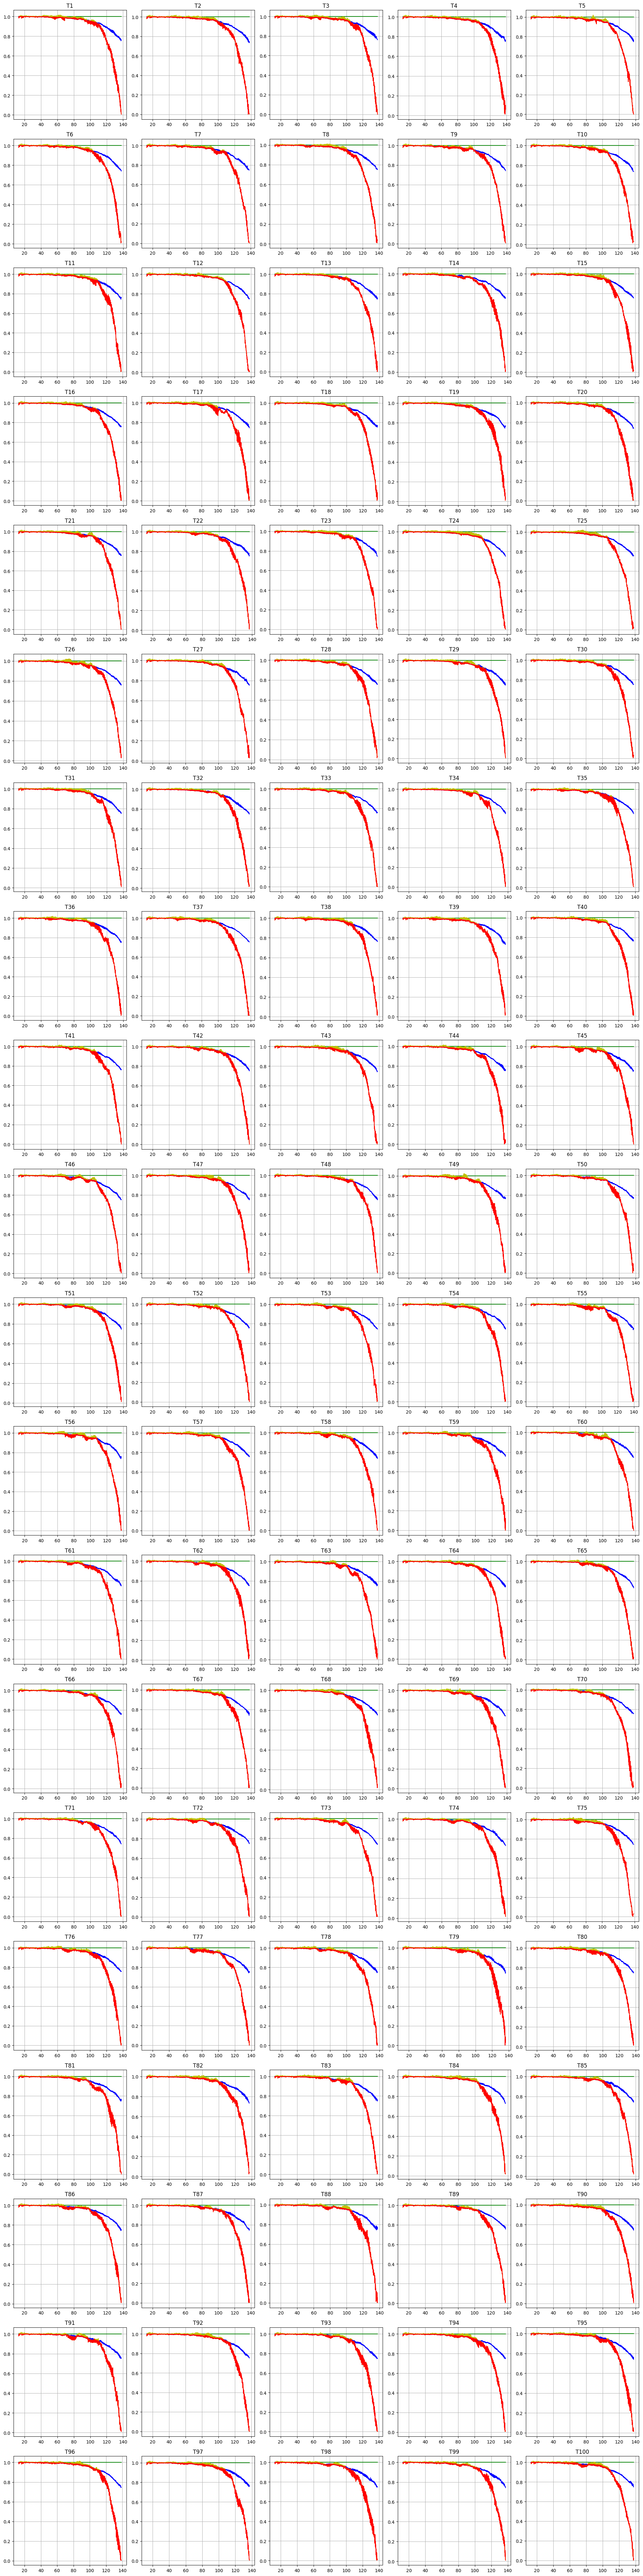

In [28]:
plot3 = MatPlot() 
plot3.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX=timeDraw, color=['g','b', 'y','r'], numRow=20, numCol=5)

In [29]:
# plot4 = MatPlot()
# plot4.subPlotMultiImg(inY = [ rulEnv1["Sys"]],  inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [30]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 4

In [31]:
environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:41053||2025-06-12 15:14:25,189-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:14:25,825-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:14:26,268-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------


... (190 outputs left out)

Process:41053||2025-06-12 15:15:01,644-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1077, 1, 45)
(1077, 128, 45)
(1077, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1077, 1, 45)
(1077, 128, 45)
(1077, 128, 45)
-------------------------------
Getting the HI at the idx 99
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------


Process:41053||2025-06-12 15:15:02,161-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------


In [32]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
# dfHI["reacHI"]  = dfHI["reacHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sepHI"]   = dfHI["sepHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["stripHI"] = dfHI["stripHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sysHI"]   = dfHI["sysHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data


dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.43585837
Average Trendability: 0.9526829177332355
Average Monotonicity: 1.0
------------------ Separator -----------------
Average Robustness: 0.45507938
Average Trendability: 0.8763388278997164
Average Monotonicity: 1.0
------------------ Stripper -----------------
Average Robustness: 0.52642965
Average Trendability: 0.656607959816525
Average Monotonicity: 0.6745588235294118
------------------ System -----------------
Average Robustness: 0.52225953
Average Trendability: 0.7237877142818151
Average Monotonicity: 1.0


In [33]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 2.7651451976602033


In [34]:
# plot1 = MatPlot()
# plot1.plot_HI_by_id(
#     dfHI,
#     hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
#     num_rows=5,
#     num_cols=20,
#     colors=['green','blue', 'yellow','red'],
#     title="Health Indicators per Unit",
#     y_lim=[0, 1]  # adjust if needed
# )


In [35]:
# plot5 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [36]:
# plot6 = MatPlot()
# plot6.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [37]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])